# Functional forms for the wide-prior ROC AUC frontier (Figure 7, Table 4)

Fits the forms of `scaling/big_prior_forms.py` (Appendix C), writes Table 4 and draws Figure 7.

In [1]:
from collections.abc import Callable
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

from scaling import big_prior_forms as bpf
from scaling.big_prior_forms import AUC, FLOPS, FORMS, PLOT_GRID, Form, predict

mpl.rcParams.update({"font.size": 8, "axes.labelsize": 8, "pdf.fonttype": 42})

In [2]:
figure_path = Path.cwd() / "figures"
figure_path.mkdir(parents=True, exist_ok=True)
table_path = Path.cwd() / "tables"
table_path.mkdir(parents=True, exist_ok=True)

result = bpf.run("../data/nanotabpfn_model_tabiclv1_prior.csv")
data, total, params, summary = (result[k] for k in ("data", "total", "params", "summary"))
forms = {f.key: f for f in FORMS}

Logistic, notebook start grid    RMSE 0.0453  backtest MAE 0.492


Logistic                         RMSE 0.0140  backtest MAE 0.024


Power law + deficit              RMSE 0.0048  backtest MAE 0.004


Two logistics                    RMSE 0.0038  backtest MAE 0.008


## Table 4

In [3]:
table4 = summary[summary["key"] != "logistic_nb"].rename(
    columns={"form": "Form", "rmse": "RMSE", "backtest_mae": "Backtest MAE", "max_excess": "Max. excess"}
)[["Form", "RMSE", "Backtest MAE", "Max. excess"]]
table4.to_csv(table_path / "table4_big_prior_forms.csv", index=False)
table4

,Form,RMSE,Backtest MAE,Max. excess
1,Logistic,0.013953,0.024191,0.007888
2,Power law + deficit,0.004753,0.004328,0.029916
3,Two logistics,0.003789,0.007861,-0.001505


## Figure 7

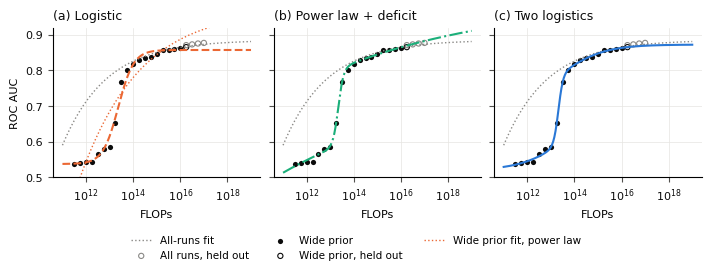

In [4]:
STYLE = {  # fixed colour and dash per form across figures; slots 1-3 of the reference palette
    "two_logistics": {"color": "#2a78d6", "linestyle": "-"},
    "logistic": {"color": "#eb6834", "linestyle": "--"},
    "gap_pl_deficit": {"color": "#1baf7a", "linestyle": "-."},
}
INK, MUTED, REFERENCE = "#0b0b0b", "#52514e", "#8a8986"


def _style_axes(ax) -> None:
    ax.set_xscale("log")
    ax.grid(True, color="#e6e5e1", linewidth=0.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelcolor=INK)


def _style_axes(ax) -> None:
    ax.set_xscale("log")
    ax.grid(True, color="#e6e5e1", linewidth=0.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelcolor=INK)


def plot_fits(forms: dict[str, Form], params: dict, data: dict, total: Callable) -> None:
    panels = [
        ("logistic", "(a) Logistic"),
        ("gap_pl_deficit", "(b) Power law + deficit"),
        ("two_logistics", "(c) Two logistics"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.6), sharey=True, layout="constrained")
    for ax, (key, title) in zip(axes, panels):
        ax.plot(PLOT_GRID, total(PLOT_GRID), color=REFERENCE, linewidth=1.0, linestyle=":", label="All-runs fit")
        ax.scatter(
            data["all_held_out"][FLOPS],
            data["all_held_out"][AUC],
            s=14,
            facecolors="none",
            edgecolors=REFERENCE,
            linewidths=0.8,
            label="All runs, held out",
        )
        ax.scatter(data["big"][FLOPS], data["big"][AUC], s=14, color=INK, linewidths=0, label="Wide prior")
        ax.scatter(
            data["big_held_out"][FLOPS],
            data["big_held_out"][AUC],
            s=14,
            facecolors="none",
            edgecolors=INK,
            linewidths=0.8,
            label="Wide prior, held out",
        )
        ax.plot(PLOT_GRID, predict(forms[key], params[key], PLOT_GRID), linewidth=1.5, label="_nolegend_", **STYLE[key])
        if key == "logistic":
            ax.plot(
                PLOT_GRID,
                predict(forms["logistic_nb"], params["logistic_nb"], PLOT_GRID),
                linewidth=1.0,
                color=STYLE[key]["color"],
                linestyle=":",
                label="Wide prior fit, power law",
            )
        _style_axes(ax)
        ax.set_title(title, fontsize=9, loc="left", color=INK)
        ax.set_xlabel("FLOPs")
        ax.set_ylim(0.5, 0.92)
    axes[0].set_ylabel("ROC AUC")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False, fontsize=7.5)
    fig.savefig(figure_path / "big_prior_fits.pdf")
    plt.show()


plot_fits(forms, params, data, total)